<a href="https://colab.research.google.com/github/Madss28/Madss28/blob/main/Python_Data_Engineering_Pipeline_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import sqlite3
import time
from pathlib import Path

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [14]:
cities = {
    "Manchester": (53.4808, -2.2426),
    "London": (51.5074, -0.1278),
    "Birmingham": (52.4862, -1.8904),
    "Edinburgh": (55.9533, -3.1883),
    "Cardiff": (51.4816, -3.1791)
}

start_date = "2025-01-01"
end_date = "2025-12-31"

BASE_URL = "https://archive-api.open-meteo.com/v1/archive"

print("Cities:", list(cities.keys()))
print("Date range:", start_date, "to", end_date)

Cities: ['Manchester', 'London', 'Birmingham', 'Edinburgh', 'Cardiff']
Date range: 2025-01-01 to 2025-12-31


In [15]:
def extract_weather(city, latitude, longitude):

    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "daily": [
            "temperature_2m_max",
            "temperature_2m_min",
            "precipitation_sum",
            "wind_speed_10m_max"
        ],
        "timezone": "Europe/London"
    }

    response = requests.get(
        BASE_URL,
        params=params,
        timeout=60
    )

    response.raise_for_status()

    data = response.json()

    if "daily" not in data:
        raise ValueError(f"No daily data returned for {city}")

    df_city = pd.DataFrame(data["daily"])
    df_city["city"] = city

    return df_city


weather_data = []

for city, coordinates in cities.items():

    print(f"Downloading data for {city}...")

    city_df = extract_weather(
        city,
        coordinates[0],
        coordinates[1]
    )

    weather_data.append(city_df)

    time.sleep(1)

weather_raw = pd.concat(
    weather_data,
    ignore_index=True
)

print("Data extraction completed!")
print("Dataset shape:", weather_raw.shape)

display(weather_raw.head())

Data extraction completed!
Dataset shape: (1825, 6)


,time,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max,city
0,2025-01-01,10.7,-0.2,39.4,28.8,Manchester
1,2025-01-02,2.3,-2.1,0.0,4.9,Manchester
2,2025-01-03,4.1,-2.5,1.7,9.5,Manchester
3,2025-01-04,2.3,-0.2,1.4,11.2,Manchester
4,2025-01-05,2.4,1.1,29.8,23.0,Manchester


In [16]:
print("Dataset shape:", weather_raw.shape)

print("\nColumn names:")
print(weather_raw.columns.tolist())

print("\nData types:")
weather_raw.info()

print("\nMissing values:")
print(weather_raw.isnull().sum())

print("\nDuplicate rows:")
print(weather_raw.duplicated().sum())

display(weather_raw.describe())

Dataset shape: (1825, 6)

Column names:
['time', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'wind_speed_10m_max', 'city']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   time                1825 non-null   object 
 1   temperature_2m_max  1825 non-null   float64
 2   temperature_2m_min  1825 non-null   float64
 3   precipitation_sum   1825 non-null   float64
 4   wind_speed_10m_max  1825 non-null   float64
 5   city                1825 non-null   object 
dtypes: float64(4), object(2)
memory usage: 85.7+ KB

Missing values:
time                  0
temperature_2m_max    0
temperature_2m_min    0
precipitation_sum     0
wind_speed_10m_max    0
city                  0
dtype: int64

Duplicate rows:
0


,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max
count,1825.000000,1825.000000,1825.000000,1825.000000
mean,14.748932,7.832219,2.556603,18.882082
std,6.398149,5.093890,5.032993,7.566598
min,-0.200000,-7.800000,0.000000,3.900000
25%,10.000000,3.800000,0.000000,13.300000
50%,14.900000,8.000000,0.300000,17.600000
75%,19.300000,11.900000,3.100000,23.000000
max,33.600000,22.800000,49.400000,61.200000


In [17]:
# Clean and prepare the data before validation
weather_clean = weather_raw.copy()

# Rename columns
weather_clean = weather_clean.rename(columns={
    "time": "date",
    "temperature_2m_max": "temp_max_c",
    "temperature_2m_min": "temp_min_c",
    "precipitation_sum": "precipitation_mm",
    "wind_speed_10m_max": "wind_speed_max_kmh"
})

# Convert date column to datetime
weather_clean["date"] = pd.to_datetime(weather_clean["date"])

# Calculate average temperature midpoint
weather_clean["temp_avg_c"] = (weather_clean["temp_max_c"] + weather_clean["temp_min_c"]) / 2

# Extract month and year
weather_clean["month"] = weather_clean["date"].dt.month
weather_clean["year"] = weather_clean["date"].dt.year

# Check that maximum temperature is not below minimum
assert (
    weather_clean["temp_max_c"] >=
    weather_clean["temp_min_c"]
).all(), "Invalid temperature values found"

# Check for duplicate city-date combinations
assert not weather_clean.duplicated(
    subset=["city", "date"]
).any(), "Duplicate records found"

# Check for negative precipitation
assert (
    weather_clean["precipitation_mm"].dropna() >= 0
).all(), "Negative precipitation found"

# Check date range
assert weather_clean["date"].between(
    pd.Timestamp(start_date),
    pd.Timestamp(end_date)
).all(), "Dates outside requested range"

print("All data validation checks passed!")

All data validation checks passed!


In [18]:
conn = sqlite3.connect("weather_pipeline.db")

cursor = conn.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS daily_weather (
    city TEXT NOT NULL,
    date TEXT NOT NULL,
    temp_max_c REAL,
    temp_min_c REAL,
    temp_avg_c REAL,
    precipitation_mm REAL,
    wind_speed_max_kmh REAL,
    month INTEGER,
    year INTEGER,
    PRIMARY KEY (city, date)
)
""")

records = weather_clean.copy()

records["date"] = records["date"].dt.strftime(
    "%Y-%m-%d"
)

rows = list(
    records[
        [
            "city", "date",
            "temp_max_c", "temp_min_c",
            "temp_avg_c", "precipitation_mm",
            "wind_speed_max_kmh",
            "month", "year"
        ]
    ].itertuples(index=False, name=None)
)

cursor.executemany("""
INSERT OR REPLACE INTO daily_weather
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
""", rows)

conn.commit()

print("Records loaded into SQLite database!")

Records loaded into SQLite database!


In [19]:
query = """
SELECT
    city,
    ROUND(AVG(temp_avg_c), 2) AS avg_temperature_c,
    ROUND(SUM(precipitation_mm), 2) AS total_rainfall_mm,
    ROUND(MAX(temp_max_c), 2) AS highest_temperature_c
FROM daily_weather
GROUP BY city
ORDER BY avg_temperature_c DESC
"""

city_summary = pd.read_sql_query(
    query,
    conn
)

display(city_summary)

,city,avg_temperature_c,total_rainfall_mm,highest_temperature_c
0,London,12.41,613.4,33.6
1,Cardiff,11.52,1306.7,32.3
2,Manchester,11.21,1144.1,30.8
3,Birmingham,11.07,728.7,32.9
4,Edinburgh,10.24,872.9,29.5


In [20]:
query_monthly = """
SELECT
    city,
    month,
    ROUND(AVG(temp_avg_c), 2) AS avg_temperature_c,
    ROUND(SUM(precipitation_mm), 2) AS rainfall_mm
FROM daily_weather
GROUP BY city, month
ORDER BY city, month
"""

monthly_summary = pd.read_sql_query(
    query_monthly,
    conn
)

display(monthly_summary.head(15))

,city,month,avg_temperature_c,rainfall_mm
0,Birmingham,1,3.03,79.2
1,Birmingham,2,4.64,55.9
2,Birmingham,3,7.56,15.1
3,Birmingham,4,10.77,28.2
4,Birmingham,5,13.61,44.1
5,Birmingham,6,17.56,38.2
6,Birmingham,7,18.54,42.0
7,Birmingham,8,18.14,31.9
8,Birmingham,9,13.49,66.1
9,Birmingham,10,11.03,64.7


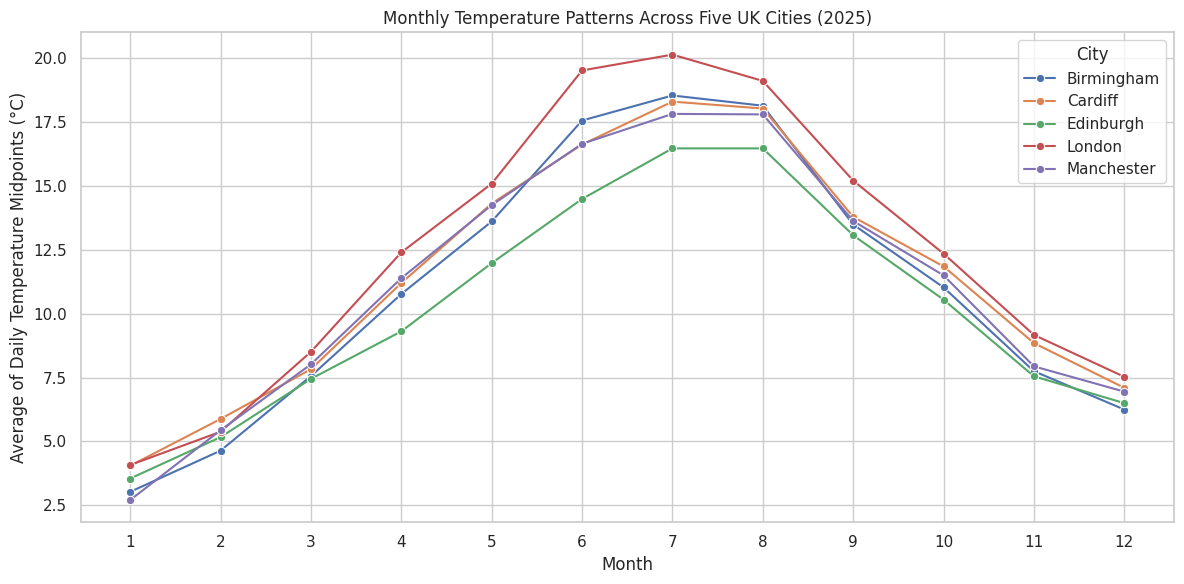

In [21]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_summary,
    x="month",
    y="avg_temperature_c",
    hue="city",
    marker="o"
)

plt.title(
    "Monthly Temperature Patterns Across Five UK Cities (2025)"
)

plt.xlabel("Month")
plt.ylabel("Average of Daily Temperature Midpoints (°C)")

plt.xticks(range(1, 13))
plt.legend(title="City")

plt.tight_layout()
plt.show()

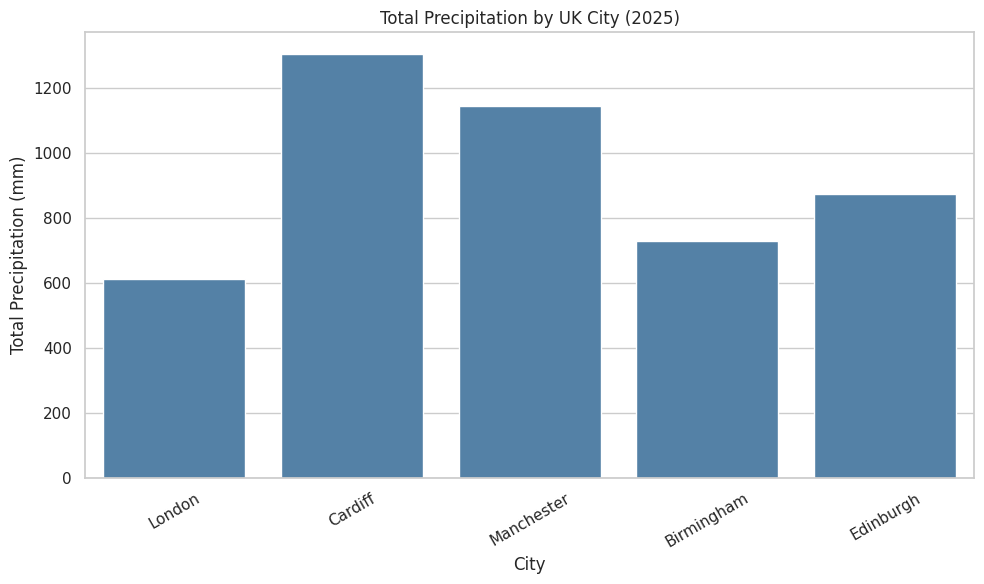

In [22]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=city_summary,
    x="city",
    y="total_rainfall_mm",
    color="steelblue"
)

plt.title("Total Precipitation by UK City (2025)")
plt.xlabel("City")
plt.ylabel("Total Precipitation (mm)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

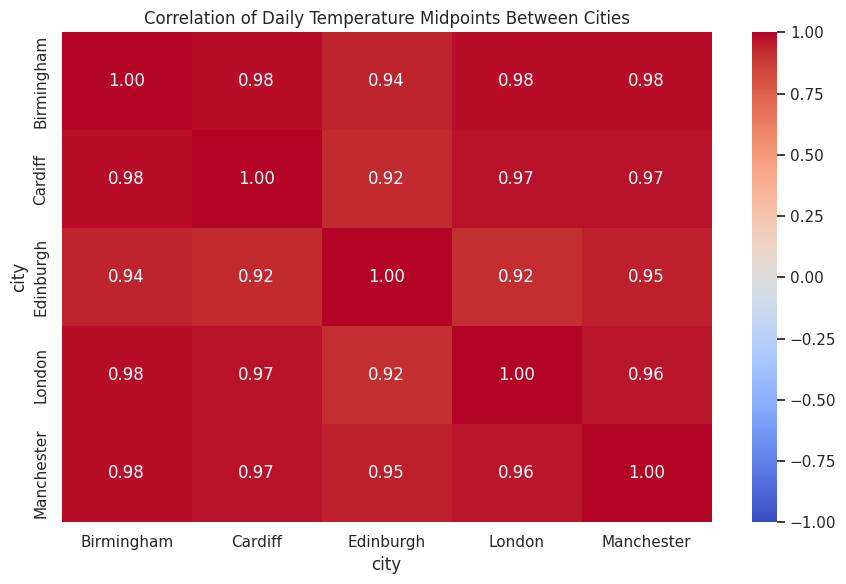

In [23]:
temperature_pivot = weather_clean.pivot(
    index="date",
    columns="city",
    values="temp_avg_c"
)

correlation_matrix = temperature_pivot.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation of Daily Temperature Midpoints Between Cities")

plt.tight_layout()
plt.show()

In [24]:
from google.colab import files
import os

os.makedirs("outputs", exist_ok=True)

# Save cleaned dataset
weather_clean.to_csv(
    "outputs/cleaned_weather_data.csv",
    index=False
)

# Save SQL analysis results
city_summary.to_csv(
    "outputs/city_weather_summary.csv",
    index=False
)

monthly_summary.to_csv(
    "outputs/monthly_weather_summary.csv",
    index=False
)

# Save correlation matrix
correlation_matrix.to_csv(
    "outputs/temperature_correlations.csv"
)

conn.commit()
conn.close()

print("All project files saved successfully!")

All project files saved successfully!


In [25]:
import shutil

# Copy database into outputs folder
shutil.copy(
    "weather_pipeline.db",
    "outputs/weather_pipeline.db"
)

# Create ZIP archive
shutil.make_archive(
    "weather_pipeline_outputs",
    "zip",
    "outputs"
)

# Download ZIP
files.download("weather_pipeline_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Project Overview

Developed an end-to-end ETL (Extract, Transform, Load) pipeline using Python to collect historical weather data for five UK cities through the Open-Meteo API. The project involves data extraction, cleaning, validation and storage in an SQLite database, followed by SQL-based analysis and visualisation using Pandas, Matplotlib and Seaborn.

The pipeline explores temperature patterns, rainfall variations and correlations between cities, demonstrating practical skills in API integration, database management, data processing and exploratory data analysis.

Technologies: Python, Pandas, NumPy, SQL, SQLite, REST API, Matplotlib, Seaborn, Google Colab.